In [1]:
import sys
sys.path.append('../')
import numpy as np
import pandas as pd
from exp_utils import CounterPlotNice
from sklearn.ensemble import RandomForestClassifier

In [2]:
# Download wine dataset
! wget https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv

# Read wine dataset
wine = pd.read_csv('winequality-red.csv', sep=';')

X, y = wine.drop('quality', axis=1), wine['quality']

# Transform X to numpy
X  = X.to_numpy()
# Transform y to binary
y = np.where(y > 5, 1, 0)

'wget' is not recognized as an internal or external command,
operable program or batch file.


In [3]:
# Make RF model for noisy dataset
model = RandomForestClassifier(random_state=42)

In [4]:
model.fit(X, y)

RandomForestClassifier(random_state=42)

In [5]:
exp_nice = CounterPlotNice(
    predict_fn=model.predict_proba,
    X_train=X,
    y_train=y,
    cat_feat=[])

In [6]:
# Select case with negative countershapley value
counterplot = exp_nice.explain(
    np.array([X[533]])
)[0]

Runtime is dominated by `generate_contribution_graph`, which needs to iterate all subcoalition combinations and run model inference once per combination.

In [7]:
import cProfile, pstats
from counterplots.utils.process import calc_shapley_values_between, create_adapted_model_and_class

def get_function_stats(stats, function_name):
    """Extract pstatsb for a specific function."""
    for func, (primitive_calls, total_calls, total_time, cumulative_time, callers) in stats.stats.items():
        if function_name in func[2]:  # func[2] is the function name
            return {
                'function': func,
                'total_calls': total_calls,
                'primitive_calls': primitive_calls,
                'total_time': total_time,
                'cumulative_time': cumulative_time
            }
    return None

def profile_calc_shapley(f, model, size=1, n=None):
    cf = f.copy()
    for i in range(size): cf[i] *= 1.1
    profiler = cProfile.Profile()
    profiler.enable()

    adapted_model, adapted_class = create_adapted_model_and_class(f, model.predict_proba, [0, 1])
    calc_shapley_values_between(
        f, 
        cf,
        predict_fn=adapted_model,
        sample_kwargs = {'n': n} if n is not None else None
    )

    profiler.disable()
    return pstats.Stats(profiler)

## Benchmark calculating exact Shapley values

In [ ]:
def write_perf_shapley(sizes, n=None):
    import time

    for size in sizes:
        nruns = 100//size  # reasonable sample size
        cum_times, times, ncalls = [], []
        stats_objects = []
        start = time.time()  # simply for output, not for profiling
        for run in range(nruns):
            stats = profile_calc_shapley(  # this is the actual profiles
                counterplot.factual,
                model,
                size=size,
                n=n
            )
            stats_objects.append(stats)
        
        print(f"Finished benchmarking size {size} after {time.time() - start:.4f} seconds ({nruns} runs)")
        print("Extracting and writing data")
        for stats in stats_objects:
            times.append(get_function_stats(stats, "predict_proba")['cumulative_time'])
            times.append(get_function_stats(stats, "predict_proba")['cumulative_time'])
            ncalls.append(get_function_stats(stats, "predict_proba")['total_calls'])
        fname = f"benchmarks/size{size}"
        if n is not None: fname += f"_sample={n}"
        fname += ".txt"
        with open(fname, "w+") as of:
            for t1, t2, c in zip(times, ncalls):
                of.write(f"{t}\t{c}\n")

In [25]:
def write_perf_shapley(sizes, n=None):
    import time
    import pandas as pd

    records = []

    for size in sizes:
        nruns = 100 // size  # reasonable sample size
        stats_objects = []

        start = time.time()
        for _ in range(nruns):
            stats = profile_calc_shapley(
                counterplot.factual,
                model,
                size=size,
                n=n
            )
            stats_objects.append(stats)

        print(
            f"Finished benchmarking size {size} "
            f"after {time.time() - start:.4f} seconds ({nruns} runs)"
        )
        print("Extracting data")

        for run_id, stats in enumerate(stats_objects):
            fs = get_function_stats(stats, "predict_proba")
            records.append({
                "size": size,
                "run": run_id,
                "cumulative_time": fs["cumulative_time"],
                "total_time": fs["total_time"],
                "total_calls": fs["total_calls"],
            })

    df = pd.DataFrame.from_records(records)

    for size, g in df.groupby("size"):
        fname = f"benchmarks/size{size}"
        if n is not None: fname += f"_sample={n}"
        fname += ".txt"

        g.to_csv(
            fname,
            sep="\t",
            index=False,
        )

In [26]:
sizes_exact = range(1, 12)
write_perf_shapley(sizes_exact)

Finished benchmarking size 1 after 2.2144 seconds (100 runs)
Extracting data
Finished benchmarking size 2 after 1.7190 seconds (50 runs)
Extracting data
Finished benchmarking size 3 after 2.0672 seconds (33 runs)
Extracting data
Finished benchmarking size 4 after 2.8515 seconds (25 runs)
Extracting data
Finished benchmarking size 5 after 4.4670 seconds (20 runs)
Extracting data
Finished benchmarking size 6 after 6.9676 seconds (16 runs)
Extracting data
Finished benchmarking size 7 after 12.1167 seconds (14 runs)
Extracting data
Finished benchmarking size 8 after 20.6003 seconds (12 runs)
Extracting data
Finished benchmarking size 9 after 83.3783 seconds (11 runs)
Extracting data
Finished benchmarking size 10 after 117.4482 seconds (10 runs)
Extracting data


KeyboardInterrupt: 

## Benchmark calculating approximate Shapley values

In [ ]:
SAMPLE_RATIOS = (.2, .3, .4, .5)
sizes_approx = range(3, 12)
for sr in SAMPLE_RATIOS:
    print("Benchmarking sample ratio {}".format(sr))
    write_perf_shapley(sizes_approx, n=sr)

Benchmarking sample ratio 0.2


Finished benchmarking size 3 after 0.0674 seconds (33 runs)
Extracting and writing data
Finished benchmarking size 4 after 0.0941 seconds (25 runs)
Extracting and writing data
Finished benchmarking size 5 after 0.1839 seconds (20 runs)
Extracting and writing data
Finished benchmarking size 6 after 0.3324 seconds (16 runs)
Extracting and writing data
Finished benchmarking size 7 after 0.6970 seconds (14 runs)
Extracting and writing data
Finished benchmarking size 8 after 1.4333 seconds (12 runs)
Extracting and writing data
Finished benchmarking size 9 after 3.0223 seconds (11 runs)
Extracting and writing data
Finished benchmarking size 10 after 5.8828 seconds (10 runs)
Extracting and writing data
Finished benchmarking size 11 after 12.8937 seconds (9 runs)
Extracting and writing data
Benchmarking sample ratio 0.3
Finished benchmarking size 3 after 0.0663 seconds (33 runs)
Extracting and writing data
Finished benchmarking size 4 after 0.1107 seconds (25 runs)
Extracting and writing data


## Plot benchmarking results

In [ ]:
PINK1 = "#ff0055"
PINK1_TR = "#ff0055d2"
RED1 = "#c20000"
BLUE1 = "#008ae7"
BLUE_TR = "#008ae7d2"
DARK_GREY = "#545454" 
LIGHT_GREY = "#e0e0e0" 

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

dfs = []
for size in sizes_exact:
    # ncalls never changes, bit silly to have as a column, but oh well
    df = pd.read_csv(
        f"benchmarks/size{size}.txt", 
        sep="\t", 
        header=None, 
        names=[f'{size}', f'ncalls_{size}']
        )
    dfs.append(df[f'{size}']*1000)  # convert to ms

times = pd.concat(dfs, axis=1)

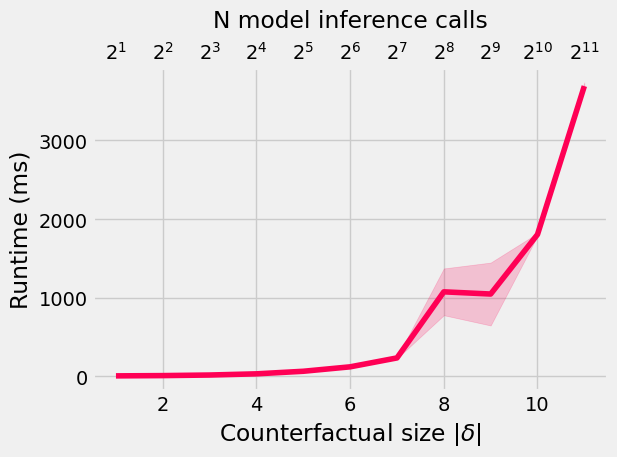

In [ ]:
m, s = times.mean(), times.std()

fig, ax1 = plt.subplots()
ax1.plot(sizes_exact, m, c=PINK1)
plt.fill_between(
    sizes_exact,
    m-s, m+s,
    alpha=.2,
    color=PINK1
)

ax2 = ax1.secondary_xaxis('top')
ax2.set_xticks(
    sizes_exact, 
    [f"$2^{{{k}}}$" for k in sizes_exact]
)
ax2.set_xlabel('N model inference calls', labelpad=10)
ax1.set_xlabel("Counterfactual size $|\delta|$")
ax1.set_ylabel("Runtime (ms)")

plt.tight_layout()
plt.show()
fig.savefig("perf.png", dpi=300)

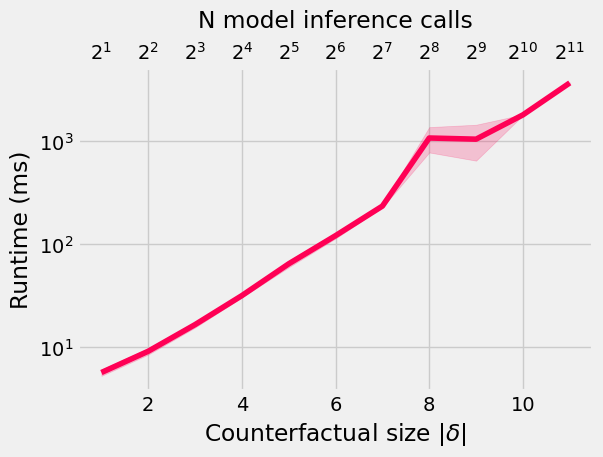

In [ ]:
m, s = times.mean(), times.std()

fig, ax1 = plt.subplots()
ax1.plot(sizes_exact, m, c=PINK1)
plt.fill_between(
    sizes_exact,
    m-s, m+s,
    alpha=.2,
    color=PINK1
)

ax2 = ax1.secondary_xaxis('top')
ax2.set_xticks(
    sizes_exact, 
    [f"$2^{{{k}}}$" for k in sizes_exact]
)
ax2.set_xlabel('N model inference calls', labelpad=10)
ax1.set_xlabel("Counterfactual size $|\delta|$")
ax1.set_ylabel("Runtime (ms)")

plt.tight_layout()
plt.yscale("log")
fig.savefig("perf_log.png", dpi=300)
plt.show()

For a default random forest classifier, it tenfolds about every increase of 4. So a CFE of size 19 (!!) would take about 5 seconds to calculate the Shapley values for in this case.

For other models, you would have to multiply this value by how much longer inference takes.